In [1]:
import sys,os
ROOT = r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Analysis"
sys.path.append(os.path.abspath(ROOT))
from functions.ST002118 import *

untargeted_data = pd.read_csv(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\Untargeted\ST002118_Untargeted_Reference_Copy.csv").set_index("SID_MW")
targeted_data = pd.read_excel(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\Targeted\TARGETED_DATA_WIDE_07132026.xlsx")
targeted_data = targeted_data.set_index("SID_MW")
annotations = pd.read_excel(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\Annotations\All ADAP IDs and Annotations Lichtveld 09JUL26.xlsx")
annotations = annotations.set_index("query_signal_name")
epi_data = pd.read_csv(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\EPI_DATA\2254_EPI_DATA.csv")
covariates = {"MaternalAgeAtIntake":"v107","MaternalEducationLevel":"v112a","Ethnicity":"v113c","BMI":"v111c"}

In [2]:
variable_map = {"v107":"MaternalAgeAtIntake",
                "v110":"Marital Status",
                "v111a":"length(cm)",
                "v111b":"CurrentWeight(kg)",
                "v111c":"BMI",
                "v112a":"Education7Categories",
                "v113c":"Ethnicity7Categories",
                "v115a":"HouseholdIncome8Categories",
                "v118b":"PreviousLiveBirths",
                "v118a":"PreviousPregnancies",
                "v140n1":"PercievedStressScore",
                "v150n2":"ProbableDepression"
}
birth_outcomes_map = {'b028a':"StatusAtBirth",
                      "b030":"GenderBaby",
                      "b031":"Birthweight(grams)",
                      "b031a": "BirthweightLessThan2500g",
                      "b034b":"GestationalAgeAtBirth",
                      "b035b":"APGARScoreAt5min",
                      "b040":"AdverseBirthOutcome",
                      "b035d":"APGARScoreLessThan7At5min",
                      "b034c":"PretermBirthLessThan37weeks"
                      }
epi_data = epi_data.rename(columns=variable_map)
epi_data = epi_data.rename(columns=birth_outcomes_map)
covariates = ['PID','MaternalAgeAtIntake',"BMI","Education7Categories","Ethnicity7Categories","HouseholdIncome8Categories"]
covariates = epi_data.loc[:,covariates]

In [3]:
metadata = untargeted_data[['Trimester','PID']].copy()
metadata['Hg'] = targeted_data['Hg (ng/mL)']
metadata['HgExposure'] = np.where(metadata['Hg'] <= 5.8,"normal","high")
metadata = metadata.dropna(subset=["Hg"])
metadata = pd.merge(metadata,covariates,right_on='PID',left_on="PID",how='inner')

In [4]:
untargeted_data['CompositeKey'] = untargeted_data['PID'].astype(str) + "_" + np.where(untargeted_data['Trimester'] == "3rd","1","0")
metadata['CompositeKey'] = metadata['PID'].astype(str) + "_" + np.where(metadata['Trimester'] == "3rd","1","0")

In [5]:
untargeted_data = untargeted_data.reset_index(drop=True).drop(columns=['PID','Trimester']).set_index("CompositeKey")
metadata.set_index("CompositeKey",inplace=True)

In [6]:
metadata_t1 = metadata[metadata['Trimester'] == "1st/2nd"]
untargeted_data_t1 = untargeted_data.loc[metadata_t1.index,:]

metadata_t2 = metadata[metadata['Trimester'] == "3rd"]
untargeted_data_t2 = untargeted_data.loc[metadata_t2.index,:]

In [9]:
obj = DifferentialAbundance(data=untargeted_data_t1,metadata=metadata_t1)
ttest_hg_t1 = obj.fit(test='ttest',contrast=("HgExposure","high","normal"),equal_var=True,covariates=metadata_t1.columns[4:].tolist())
ttest_hg_t1 = ttest_hg_t1[(ttest_hg_t1['high_mean'] != 0) & (ttest_hg_t1['normal_mean'] != 0)]

obj = DifferentialAbundance(data=untargeted_data_t2,metadata=metadata_t2)
ttest_hg_t2 = obj.fit(test='ttest',contrast=("HgExposure","high","normal"),equal_var=True,covariates=metadata_t2.columns[4:].tolist())
ttest_hg_t2 = ttest_hg_t2[(ttest_hg_t2['high_mean'] != 0) & (ttest_hg_t2['normal_mean'] != 0)]

Contrast: HgExposure[high vs normal]  (high: n=57, normal: n=253)  test=ttest  covariates=['MaternalAgeAtIntake', 'BMI', 'Education7Categories', 'Ethnicity7Categories', 'HouseholdIncome8Categories']  dof=303
Contrast: HgExposure[high vs normal]  (high: n=42, normal: n=204)  test=ttest  covariates=['MaternalAgeAtIntake', 'BMI', 'Education7Categories', 'Ethnicity7Categories', 'HouseholdIncome8Categories']  dof=239


In [10]:
BIOMARKERS = {"EPA[OL-1]":["15.53_285.2210m/z","15.91_302.2244n"],
              "ArachidonicAcid[OL-1]":["16.07_269.2260m/z","16.23_304.2395n"],
              "DHA[OL-1]":["16.21_328.2395n"],
              "DPA[OL-1]": ["16.39_330.2554n"],
              "AdrenicAcid[OL-1]":["16.64_332.2711n"],
              "LinoleicAcid[OL-1]":["16.24_280.2401n","16.43_263.2366m/z"],
              "Linolenic[OL-1]":["15.91_278.2243n","16.45_306.2554n"],
              "TMAO[OL-1]":["0.64_75.0684n"],
              "1-MethylHistidine[OL-2b]": ["1.67_169.0851n"]
              }
signal_to_name = {
    signal: name
    for name, signals in BIOMARKERS.items()
    for signal in signals
}

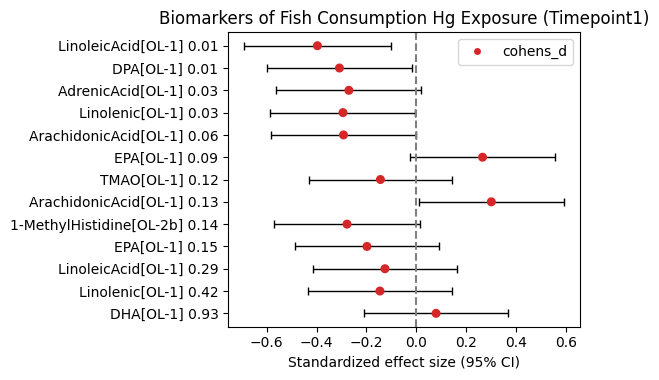

In [15]:
from itertools import chain
bm = ttest_hg_t1.loc[list(chain.from_iterable(BIOMARKERS.values())),:]
bm.index = bm.index.map(signal_to_name)
bm.index = bm.index + " " + np.round(bm['p_value'],2).astype(str)
forest_plot = DifferentialAbundance.forest_plot(bm,effect_measure='cohens_d',backend='seaborn',title='Biomarkers of Fish Consumption Hg Exposure (Timepoint1)',equal_var=False)

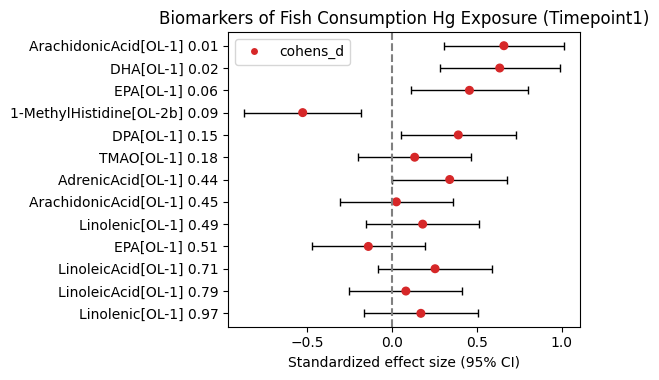

In [14]:
from itertools import chain
bm = ttest_hg_t2.loc[list(chain.from_iterable(BIOMARKERS.values())),:]
bm.index = bm.index.map(signal_to_name)
bm.index = bm.index + " " + np.round(bm['p_value'],2).astype(str)
forest_plot = DifferentialAbundance.forest_plot(bm,effect_measure='cohens_d',backend='seaborn',title='Biomarkers of Fish Consumption Hg Exposure (Timepoint1)',equal_var=False)

,effect_size,ci_lower,ci_upper,stat,n,p_value,p_adj
11.61_240.0996n,0.857553,0.516844,1.198262,cohens_d,246.0,0.000367,0.050982
4.92_246.1699m/z,0.811940,0.472111,1.151768,cohens_d,246.0,0.001231,0.077243
11.87_538.2813m/z,-0.734499,-1.072938,-0.396061,cohens_d,246.0,0.001323,0.079697
10.53_362.2090n,-0.514265,-0.849490,-0.179040,cohens_d,246.0,0.001526,0.085412
3.01_182.0440n,-0.583748,-0.919867,-0.247628,cohens_d,246.0,0.001980,0.098410
...,...,...,...,...,...,...,...
14.72_292.2039n,0.150033,-0.182339,0.482405,cohens_d,246.0,0.982966,0.999314
4.57_243.1470n,-0.058192,-0.390337,0.273954,cohens_d,246.0,0.986267,0.999314
3.68_113.0597m/z,0.044254,-0.287874,0.376383,cohens_d,246.0,0.993827,0.999314
0.62_119.0582n,0.118439,-0.213832,0.450711,cohens_d,246.0,0.994472,0.999314


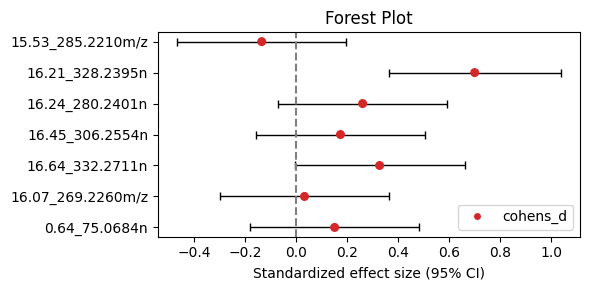

In [ ]:
DifferentialAbundance.forest_plot(j[j["highest_OL"] == "OL_1"],effect_measure='cohens_d',features=BIOMARKERS.values())

In [298]:
BIOMARKERS

{'EPA[OL-1]': '15.53_285.2210m/z',
 'DHA[OL-1]': '16.21_328.2395n',
 'Linoleic Acid[OL-1]': '16.24_280.2401n',
 'cis-8,11,14-ETE[PD_A]': '16.45_306.2554n',
 'Adrenic Acid[OL-1]': '16.64_332.2711n',
 'Arachidonic Acid[OL-1]': '16.07_269.2260m/z',
 'TMAO[OL-1]': '0.64_75.0684n'}

In [285]:
mummichog = ttest_hg_t2[['Signals','t_stat','p_value','p_adj','log2FC']].copy()
mummichog[['retention time','m/z']] = mummichog['Signals'].str.split("_",expand=True)
mummichog['m/z'] = mummichog['m/z'].str.replace('m/z',"")
mummichog['m/z'] = mummichog['m/z'].str.replace("n","")
mask = mummichog['Signals'].str.contains("n")
mummichog.loc[mask, 'm/z'] = mummichog.loc[mask, 'm/z'].astype(float) + 1.0074
col_map = {"t_stat":"t.stat","p_value":"p.value","retention time":"r.t","m/z":"m.z"}
mummichog = mummichog.rename(columns=col_map)
mummichog = mummichog.loc[:,list(col_map.values())]
mummichog.to_csv(f'Hg_covariates__t2_mummichog_input.txt',sep='\t',index=False)